<a href="https://colab.research.google.com/github/vijayaragavanpandiyan555-collab/Stock-market-analysis-/blob/main/Stock_market_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset not found at /content/stock_data.csv. Generating dummy stock data for demonstration...
First 5 rows:
         Date       Close
0  2023-01-01  101.493428
1  2023-01-02  101.716900
2  2023-01-03  103.512277
3  2023-01-04  107.058336
4  2023-01-05  107.090030

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    100 non-null    object 
 1   Close   100 non-null    float64
dtypes: float64(1), object(1)
memory usage: 1.7+ KB
None

Missing Values:
Date     0
Close    0
dtype: int64

Dataset Description:
                      Date       Close
count                  100  100.000000
mean   2023-02-19 12:00:00  112.439635
min    2023-01-01 00:00:00  101.493428
25%    2023-01-25 18:00:00  105.258153
50%    2023-02-19 12:00:00  108.602675
75%    2023-03-16 06:00:00  121.046250
max    2023-04-10 00:00:00  130.345969
std                

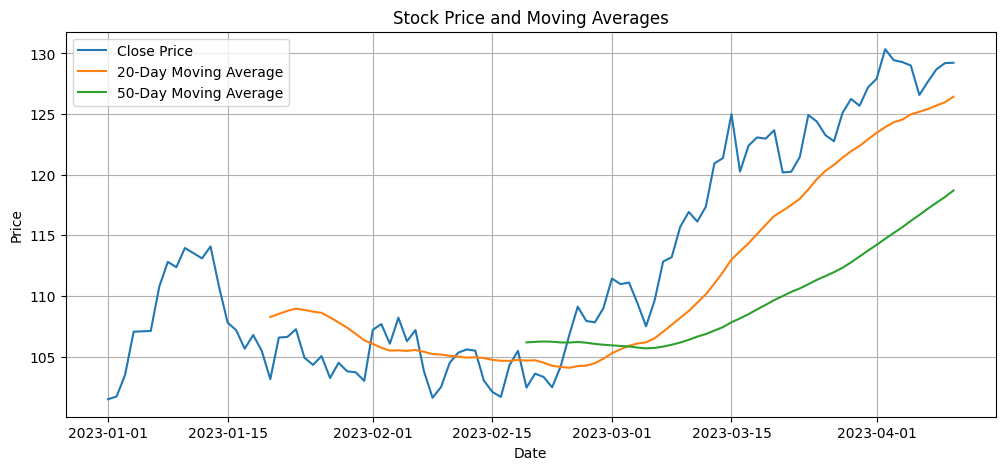


----- MODEL RESULTS -----
MAE : 10.396097872002287
RMSE: 10.620288650336276


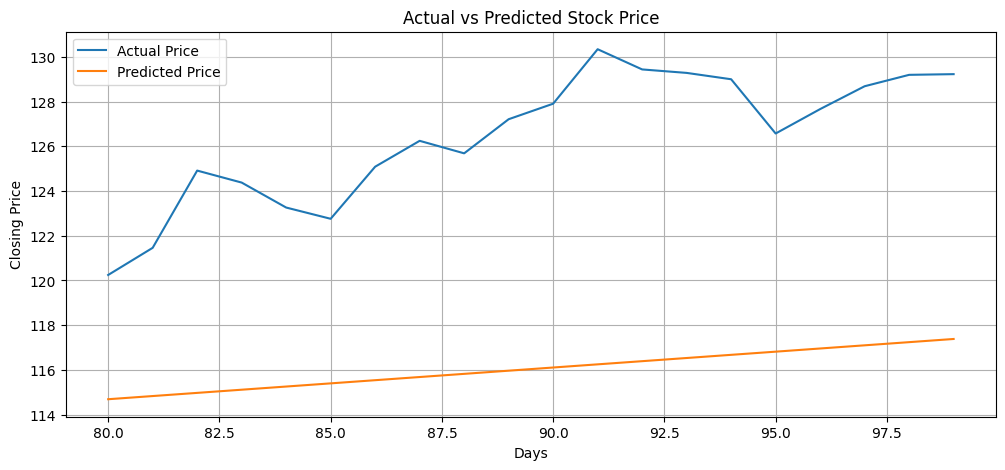


Stock Market Analysis Completed Successfully!


In [ ]:
# STOCK MARKET ANALYSIS USING PYTHON IN AI & ML

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Path to the dataset
dataset_path = '/content/stock_data.csv'

# Generate dummy data if file does not exist to avoid FileNotFoundError
if not os.path.exists(dataset_path):
    print(f"Dataset not found at {dataset_path}. Generating dummy stock data for demonstration...")
    np.random.seed(42)
    dates = pd.date_range(start="2023-01-01", periods=100)
    prices = 100 + np.cumsum(np.random.normal(0.5, 2, size=100))  # random walk
    dummy_df = pd.DataFrame({'Date': dates, 'Close': prices})
    dummy_df.to_csv(dataset_path, index=False)

# Load dataset
df = pd.read_csv(dataset_path)

print("First 5 rows:")
print(df.head())

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

# Data Cleaning
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date')
df = df.drop_duplicates()
df = df.dropna(subset=['Date', 'Close'])

print("\nDataset Description:")
print(df.describe())

# Moving Average
df['MA20'] = df['Close'].rolling(window=20).mean()
df['MA50'] = df['Close'].rolling(window=50).mean()

# Stock Price Visualization
plt.figure(figsize=(12, 5))
plt.plot(df['Date'], df['Close'], label='Close Price')
plt.plot(df['Date'], df['MA20'], label='20-Day Moving Average')
plt.plot(df['Date'], df['MA50'], label='50-Day Moving Average')

plt.xlabel('Date')
plt.ylabel('Price')
plt.title('Stock Price and Moving Averages')
plt.legend()
plt.grid()
plt.show()

# Prepare data for Machine Learning
df['Day'] = (df['Date'] - df['Date'].min()).dt.days

model_df = df[['Day', 'Close']].dropna()

X = model_df[['Day']]
y = model_df['Close']

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False
)

# Linear Regression Model
model = LinearRegression()
model.fit(X_train, y_train)

# Prediction
pred = model.predict(X_test)

# Model Evaluation
mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))

print("\n----- MODEL RESULTS -----")
print("MAE :", mae)
print("RMSE:", rmse)

# Actual vs Predicted Price
plt.figure(figsize=(12, 5))
plt.plot(X_test['Day'], y_test.values, label='Actual Price')
plt.plot(X_test['Day'], pred, label='Predicted Price')

plt.xlabel('Days')
plt.ylabel('Closing Price')
plt.title('Actual vs Predicted Stock Price')
plt.legend()
plt.grid()
plt.show()

print("\nStock Market Analysis Completed Successfully!")